In [1]:
import marimo as mo

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
from kaggle_api import fetch_dataset

df_train, df_test = fetch_dataset()

cols_categorical = "x4 x5 x10 Y".split()

df_train["Y"] = df_train["Y"].astype("category")

for df in (df_train, df_test):
    for _col in cols_categorical[:-1]:
        df[_col] = df[_col].astype("category")

    df.insert(10, column="x1a", value=(df.x1 >= 0).astype(np.int8).astype("category"))

✅ data loaded!


# model overview

- type - GAM logistic regression
- predictor selection method - manual

In [4]:
# https://pygam.readthedocs.io/en/latest/reference/_autosummary/pygam.pygam.LogisticGAM.html

from pygam import LogisticGAM, f, s, te

gam = LogisticGAM(
    # s(1 - 1)
    te(s(7 - 1), s(2 - 1))
    + te(s(7 - 1), s(3 - 1))
    + te(f(4 - 1), f(5 - 1), f(10 - 1), f(11 - 1))
    + te(s(7 - 1), s(6 - 1))
    # + s(8 - 1)
    + te(s(7 - 1), s(9 - 1))
).fit(df_train.iloc[:, df_train.columns != "Y"], df_train.Y)

gam.summary()

/tmp/nix-shell.aplRml/ipykernel_98345/4070760959.py:15: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


LogisticGAM                                                                                               
=============================================== ==========================================================
Distribution:                      BinomialDist Effective DoF:                                    225.2597
Link Function:                        LogitLink Log Likelihood:                                 -7579.3895
Number of Samples:                        15000 AIC:                                            15609.2983
                                                AICc:                                           15616.2598
                                                UBRE:                                               3.0526
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                   0.1454
Feature Function                  Lam

In [5]:
prediction = gam.predict_proba(df_test)

prediction_probs = pd.Series(prediction, index=df_test.index)
prediction_probs.describe()

count    10000.000000
mean         0.277700
std          0.173416
min          0.000998
25%          0.125458
50%          0.258710
75%          0.396869
max          0.968544
dtype: float64

# model assessment

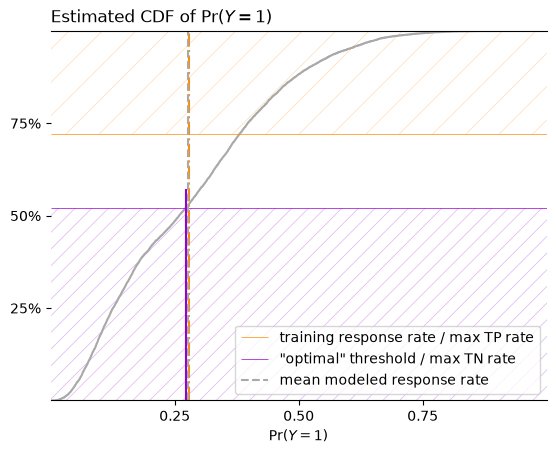

In [6]:
import threshold as th

pos_prediction_count, threshold = th.estimate_optimal_threshold(prediction_probs)

mo.output.append(pos_prediction_count)
mo.output.append(threshold)

mo.output.append(
    th.plot_probs(
        probs=prediction_probs,
        expt_prob=np.mean(df_train.Y.astype(np.int64)),
        threshold=threshold,
        pos_pred_count=pos_prediction_count,
    )
)

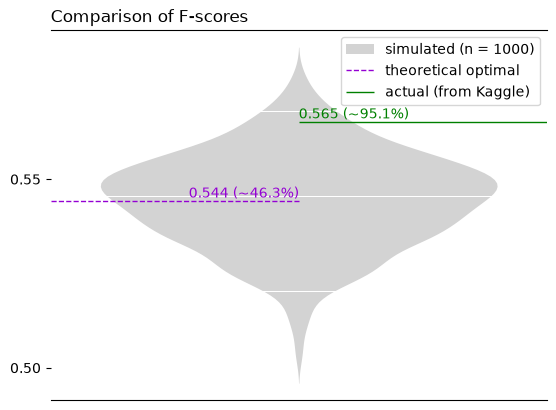

In [7]:
rng = np.random.default_rng(1)

_ = th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng,
        1000,
        prediction_probs,
        pos_prediction_count,
        report_count=(3 * len(prediction_probs)) // 10,  # reported score uses 30% of the test data
    ),
    calculated=2 * threshold,
    reported=0.56523,
)

## conclusion

- ✅ the modeled average response rate (mostly) matches the training average
- the optimal F-score is:
    - larger than the GAM model that doesn't use tensors on $x_7$
    - somewhat low, compared to e.g. random forests
- the reported F-score is:
    - ✅ within the bounds of the simulated CI
    - smaller than that of e.g. the random forests model

# make submission

In [8]:
predictions = prediction_probs.sort_values(ascending=False)
predictions.iloc[0:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0
predictions = predictions.astype(np.int8).sort_index()

predictions

ID
15001    1
15002    1
15003    0
15004    0
15005    0
        ..
24996    0
24997    1
24998    0
24999    0
25000    0
Length: 10000, dtype: int8

In [9]:
import os
import os.path
import pathlib

notebook_path = os.environ.get("JPY_SESSION_NAME")
submission_filepath = pathlib.Path(
    f"./submissions/{os.path.splitext(os.path.basename(notebook_path))[0]}.csv"
)
print(f"saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

saving submission file to submissions/model4.2_gam_binomial.csv
